# 01 Boty – wybór kont do odrzucenia

## 1. Konfiguracja

In [83]:
import sys
sys.path.append("..")

import json
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm.auto import tqdm

from src.config import CYCLES, PROCESSED_DIR, RAW_DIR, STUDY_FILES, SUBREDDITS, WINDOWS
from src.weeks import to_week_start

BOTS_DIR = PROCESSED_DIR / "bots_grid"
BOTS_DIR.mkdir(parents=True, exist_ok=True)
THRESHOLDS = [200, 500, 1000, 2000, 3000, 5000, 10000]
NAME_RE = re.compile(r"bot|auto")
SAMPLE_MIN_COMMENTS = 500
SAMPLES_PER_ACCOUNT = 2

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

## 2. Zliczenie kont w plikach (wolne)

In [84]:
author_parts, sample_rows = [], []

for subreddit, cycle in tqdm(STUDY_FILES):
    path = RAW_DIR / f"r_{subreddit}_comments_{cycle}.jsonl"
    window_start, window_end = WINDOWS[cycle]
    start_ts = pd.Timestamp(window_start).timestamp()
    end_ts = pd.Timestamp(window_end).timestamp() + 86400

    rows, texts = [], {}
    with open(path, encoding="utf-8") as file:
        for line in file:
            try:
                record = json.loads(line)
            except json.JSONDecodeError:
                continue
            author = record.get("author")
            body = record.get("body") or ""
            created = int(record["created_utc"])
            if not author or author == "[deleted]" or body.strip() in ("[deleted]", "[removed]"):
                continue
            if not start_ts <= created < end_ts:
                continue
            author = author.lower()
            rows.append((author, record.get("link_id"), created, record.get("distinguished") == "moderator"))
            first_texts = texts.setdefault(author, [])
            if len(first_texts) < SAMPLES_PER_ACCOUNT:
                first_texts.append((record["id"], body[:300]))

    df = pd.DataFrame(rows, columns=["author", "link_id", "created_utc", "moderator"])
    del rows
    df["week_start"] = to_week_start(df["created_utc"])
    by_author = df.groupby("author")
    counts = pd.DataFrame({"n": by_author.size(), "n_weeks": by_author["week_start"].nunique(),
                           "n_threads": by_author["link_id"].nunique(), "n_moderator": by_author["moderator"].sum()})
    by_week = df.groupby(["author", "week_start"]).size().reset_index(name="n_week")
    peak = by_week.sort_values("n_week", ascending=False).drop_duplicates("author").set_index("author")
    counts["max_week"] = peak["n_week"]
    counts["peak_week"] = peak["week_start"]
    counts["span_weeks"] = (by_author["week_start"].max() - by_author["week_start"].min()).dt.days // 7 + 1
    counts["share"] = counts["n"] / len(df)
    counts.insert(0, "subreddit", subreddit)
    counts.insert(1, "cycle", cycle)
    author_parts.append(counts.reset_index())

    to_review = counts.index[(counts["n"] >= SAMPLE_MIN_COMMENTS) | counts.index.str.contains(NAME_RE)]
    for author in to_review:
        for comment_id, text in texts[author]:
            sample_rows.append((subreddit, cycle, comment_id, author, text))
    del df, texts

100%|██████████| 30/30 [06:05<00:00, 12.20s/it]


In [85]:
pd.concat(author_parts, ignore_index=True).to_parquet(BOTS_DIR / "author_counts.parquet", index=False)
pd.DataFrame(sample_rows, columns=["subreddit", "cycle", "id", "author", "text"]).to_csv(BOTS_DIR / "comment_samples.csv", index=False)
len(author_parts)

30

## 3. Tabela kont

In [86]:
author_counts = pd.read_parquet(BOTS_DIR / "author_counts.parquet")
samples = pd.read_csv(BOTS_DIR / "comment_samples.csv").groupby("author")["text"].apply(list)
file_totals = author_counts.groupby(["subreddit", "cycle"])["n"].sum().rename("n_file")
n_all = int(file_totals.sum())

biggest = author_counts.loc[author_counts.groupby("author")["n"].idxmax()].set_index("author")
accounts = author_counts.groupby("author").agg(n_files=("cycle", "size"), n_total=("n", "sum"), n_moderator=("n_moderator", "sum"))
accounts["max_n"] = biggest["n"]
accounts["max_file"] = biggest["subreddit"] + " " + biggest["cycle"].astype(str)
peak_row = author_counts.loc[author_counts.groupby("author")["max_week"].idxmax()].set_index("author")
accounts["max_week"] = peak_row["max_week"]
accounts["peak_file"] = peak_row["subreddit"] + " " + peak_row["cycle"].astype(str)
accounts["peak_week"] = peak_row["peak_week"].dt.date
accounts["peak_span_weeks"] = peak_row["span_weeks"]
accounts["per_week"] = (biggest["n"] / biggest["n_weeks"]).round(1)
accounts["per_thread"] = (biggest["n"] / biggest["n_threads"]).round(1)
accounts["name_pattern"] = accounts.index.str.contains(NAME_RE)
accounts = accounts.sort_values("n_total", ascending=False)
accounts.to_parquet(BOTS_DIR / "accounts_all.parquet")
accounts[accounts["n_total"] >= 100].to_csv(BOTS_DIR / "accounts_min100.csv")
print(f"{len(accounts)} kont, {n_all} komentarzy")
accounts.head(30)

1161731 kont, 15403612 komentarzy


,n_files,n_total,n_moderator,max_n,max_file,max_week,peak_file,peak_week,peak_span_weeks,per_week,per_thread,name_pattern
author,,,,,,,,,,,,
automoderator,25,228971,228564,61417,running 2024,2531,democrats 2020,2021-01-04,105,590.5,1.0,True
chabanais,9,32881,2093,16515,Conservative 2016,587,Conservative 2012,2012-08-13,77,157.3,3.4,False
ibiteyou,8,27102,1439,10623,Republican 2016,483,Conservative 2020,2020-03-09,99,103.1,4.0,False
ultimis,7,25644,138,10613,Conservative 2020,427,Conservative 2024,2023-08-21,40,101.1,2.4,False
redbaronsbrother,4,21008,104,10101,Republican 2024,575,Republican 2024,2024-08-12,90,160.3,3.0,False
yourshoesuntied,5,20465,439,18396,running 2016,379,running 2016,2015-07-13,105,175.2,6.3,False
skarface6,4,18751,205,14448,Conservative 2020,293,Conservative 2020,2020-03-02,105,137.6,2.9,False
sloworfast,6,12803,0,6380,running 2016,272,running 2016,2016-10-17,96,72.5,5.8,False
xanthic_strath,3,12339,4672,5682,languagelearning 2022,171,languagelearning 2020,2020-04-20,62,107.2,1.2,False


## 4. Jak aktywne są konta

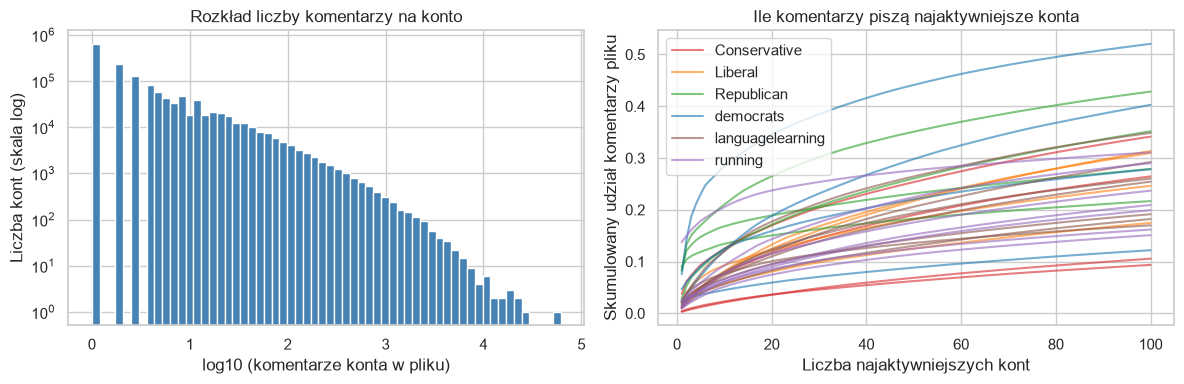

In [87]:
colors = dict(zip(SUBREDDITS, sns.color_palette("tab10")))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(author_counts["n"]), bins=60, color="steelblue")
axes[0].set_yscale("log")
axes[0].set_xlabel("log10 (komentarze konta w pliku)")
axes[0].set_ylabel("Liczba kont (skala log)")
axes[0].set_title("Rozkład liczby komentarzy na konto")
labelled = set()
for (subreddit, cycle), part in author_counts.groupby(["subreddit", "cycle"]):
    share = part["share"].sort_values(ascending=False).head(100).cumsum().to_numpy()
    axes[1].plot(np.arange(1, len(share) + 1), share, color=colors[subreddit], alpha=0.6,
                 label=None if subreddit in labelled else subreddit)
    labelled.add(subreddit)
axes[1].set_xlabel("Liczba najaktywniejszych kont")
axes[1].set_ylabel("Skumulowany udział komentarzy pliku")
axes[1].set_title("Ile komentarzy piszą najaktywniejsze konta")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Konta z „bot” lub „auto” w nazwie

In [88]:
by_name = accounts[accounts["name_pattern"]]
print(f"{len(by_name)} kont, razem {int(by_name['n_total'].sum())} komentarzy; pełna lista: accounts_all.parquet (kolumna name_pattern)")
by_name_size = by_name[by_name["n_total"] > 100]
by_name_size[["n_files", "n_total", "max_n", "max_file", "per_week", "per_thread"]].sort_values("n_total", ascending=False)

4187 kont, razem 294164 komentarzy; pełna lista: accounts_all.parquet (kolumna name_pattern)


,n_files,n_total,max_n,max_file,per_week,per_thread
author,,,,,,
automoderator,25,228971,61417,running 2024,590.5,1.0
bottlecoffee,3,6808,5108,running 2024,52.7,5.9
russiabot1776,1,5722,5722,Conservative 2020,56.7,3.3
secretsexbot,5,2729,1719,running 2016,23.2,3.9
wabbott82,4,1336,1239,Conservative 2020,22.1,1.1
robotoverlordz,4,1309,556,Conservative 2012,14.6,1.7
election_info_bot,1,1292,1292,democrats 2020,25.3,1.0
robotpettingzoo,1,835,835,running 2016,16.7,3.1
converter-bot,5,795,474,running 2020,52.7,1.7


In [89]:
comments = 3

def show_comments(by_name_size, comments, rows=None):
    if rows is None:
        rows = slice(None)
    for author in by_name_size.index[rows]:
        row = by_name_size.loc[author]
        print(f"{author} | komentarzy: {row['n_total']} | najwięcej: {row['max_n']} ({row['max_file']}) | na tydzień: {row['per_week']}")
        for text in samples.get(author, [])[:comments]:
            print("   -", textwrap.shorten(str(text), 250))
        print()

In [90]:
import random


def show_single_comment(name, comments=10):
    row = accounts.loc[name]
    print(f"{name} | komentarzy: {row['n_total']} | najwięcej: {row['max_n']} ({row['max_file']}) | na tydzień: {row['per_week']}")
    pattern = re.compile(rb'"author": *"' + re.escape(name.encode()) + rb'"', re.I)
    texts = []
    for subreddit, cycle in author_counts.loc[author_counts["author"] == name, ["subreddit", "cycle"]].itertuples(index=False):
        with open(RAW_DIR / f"r_{subreddit}_comments_{cycle}.jsonl", "rb") as file:
            texts += [json.loads(line)["body"] for line in file if pattern.search(line)]
    for text in random.Random(42).sample(texts, min(comments, len(texts))):
        print("   -", textwrap.shorten(str(text), 250))


In [91]:
show_single_comment("russiabot1776", 10)

russiabot1776 | komentarzy: 5722 | najwięcej: 5722 (Conservative 2020) | na tydzień: 56.7
   - I think that CS Lewis’ book *That Hideous Strength* is far more prophetic and terrifying than *1984*
   - The right to not die in a needless territorial war that would happen if we abandoned our ally. But it seems you are pro-war
   - And some people want murder to be legal.
   - Opinion pieces can contain facts
   - Flabbergasted is hardly a quirky word
   - It’s not so much the length of lockdown but the severity of its impact. [With the economic collapse that has already happened, the UN is predicting hundreds of thousands of deaths due to increases in levels of poverty alone. [...]
   - The democrats engaged in blatant disregard for the constitution in an attempt to overturn a fair election. They are fascistic.
   - Because to actually reach that communist utopia is impossible and to even attempt it requires an authoritarian state.
   - Throwing money at a problem rarely solves it
   - Th

In [92]:
show_comments(by_name_size, comments, rows=slice(0, 20))

automoderator | komentarzy: 228971 | najwięcej: 61417 (running 2024) | na tydzień: 590.5
   - Your submission has been automatically removed pending manual approval because your account does not meet the minimum karma or account age requirements of /r/democrats. Please collect some positive karma in other subreddits to avoid having to [...]
   - /r/democrats does not allow query strings in urls as they are often used to bypass duplicate article checks. A query string is the part of the url that follows and includes the `?` Please remove this from your url and resubmit. example: [...]
   - Your submission has been automatically removed because your account does not meet the minimum karma *and/or* account age requirements of /r/democrats. Please collect some positive karma in other subreddits to avoid having to go through the [...]

bottlecoffee | komentarzy: 6808 | najwięcej: 5108 (running 2024) | na tydzień: 52.7
   - I have a couple of race day questions. I've run a fair amount over t

In [93]:
show_comments(by_name_size, comments, rows=slice(20, 40))

sneakpeekbot | komentarzy: 345 | najwięcej: 74 (running 2018) | na tydzień: 5.3
   - **Here's a sneak peek of /r/Conservative using the [top posts](https://np.reddit.com/r/conservative/top/?sort=top&t=all) of the year!** \#1: [So let me get this straight...](http://i.imgur.com/L0p4pQA.jpg) | [3355 [...]
   - **Here's a sneak peek of /r/USMC using the [top posts](https://np.reddit.com/r/usmc/top/?sort=top&t=all) of the year!** \#1: [General Mattis selected as SecDef](https://www.washingtonpost.com/world/national-security/trump-has-chosen-retired- [...]
   - **Here's a sneak peek of /r/the_cheeto using the [top posts](https://np.reddit.com/r/the_cheeto/top/?sort=top&t=all) of all time!** \#1: [A litter of baby cheetos](http://imgur.com/wqsz9gr) | [...]

automaticwoodpecker6 | komentarzy: 339 | najwięcej: 236 (running 2022) | na tydzień: 5.8
   - I think this is a fairly logical thing to feel - from a similar experience, all I can say is it helped (and still does) to focus on enjoyment of

In [94]:
show_single_comment("robotorourke", comments)

robotorourke | komentarzy: 212 | najwięcej: 205 (Conservative 2020) | na tydzień: 4.0
   - >Beto Did you mean Robert Francis O'Rourke?
   - >Beto Did you mean Robert Francis O'Rourke?
   - >Beto Did you mean Robert Francis O'Rourke?


In [95]:
show_comments(by_name_size, comments, rows=slice(40, 60))

auto_text | komentarzy: 190 | najwięcej: 190 (running 2016) | na tydzień: 6.8
   - I wish I could be modest?
   - I don't think I would ever go to the gym if I was an attractive girl.

outline_link_bot | komentarzy: 189 | najwięcej: 124 (democrats 2020) | na tydzień: 3.0
   - > *House Democrats Plan to Request More Documents From Trump Associates* Decluttered version of this WSJ's article archived on March 20, 2019 can be viewed on https://outline.com/xmzn3C
   - > *Reports: Mueller Team Lived in Magic Fantasy World, Expected Trump to Handle Its Conclusions in Good Faith* Decluttered version of this Slate Magazine's article archived on April 04, 2019 can be viewed on https://outline.com/bJ2N2e
   - > *Deutsche Bank Staff Reportedly Saw Transfers From Kushner’s Companies to Russia as Suspicious* Decluttered version of this Slate Magazine's article archived on May 19, 2019 can be viewed on https://outline.com/hXNVsw

roboticfedora | komentarzy: 188 | najwięcej: 185 (democrats 2024) | na 

In [96]:
show_comments(by_name_size, comments, rows=slice(60, 80))

mr_dogbot | komentarzy: 133 | najwięcej: 133 (running 2018) | na tydzień: 6.3
   - It’s much like being a cult leader. Do a little light reading on L Ron Hubbard. All of his techniques are applicable to coaching runners
   - TIL there are rules here

tbotcotw | komentarzy: 129 | najwięcej: 122 (running 2012) | na tydzień: 4.7
   - It's faster than me. I did 19 miles this week at 10:17 per mile.
   - Yeah, I was working on my Ridiculously Photogenic Guy the other day... I think it came out more like a half-rabid grimace.
   - Son the Father by Fucked Up.

lobotxiii | komentarzy: 129 | najwięcej: 120 (Conservative 2020) | na tydzień: 5.0
   - It's not capitalisms fault, it's government and the federal reserve. Maybe if we didn't tax and regulate the shit out of everything we do, we wouldn't have corporations manufacture everything over seas for pennies. Wtf.. why am I being down [...]
   - Their issue is basically non existent. Their leaders are actual marxists and their martyrs are usua

In [97]:
show_comments(by_name_size, comments, rows=slice(80, 100))

49thbotdivision | komentarzy: 104 | najwięcej: 104 (Conservative 2024) | na tydzień: 14.9
   - Irish flags on Saint Paddy's day and Mexican flags at Mexican cultural events are fine At immigration rallies it's odd.
   - You don't have to fight them. The first thing they destroy with rioting is the liberal cities that enable them.

dadbot_3000 | komentarzy: 104 | najwięcej: 78 (Conservative 2020) | na tydzień: 15.6
   - Hi sorry, I'm Dad! :)
   - Hi an idiot savant, I'm Dad! :)
   - Hi looking forward to the arrests that keep going on, I'm Dad! :)

automaticff | komentarzy: 103 | najwięcej: 67 (Conservative 2020) | na tydzień: 3.9
   - This is definitely the experience I'm having in r/BlackPeopleTwitter. Give me a good argument and I can definitely be swayed. I don't belong to either party. But when you don't join the hive mind, they downvote you into oblivion. Never in a [...]
   - There goes the tolerant left being tolerant again
   - I like her a lot. Supported her when she was runni

In [98]:
show_single_comment("dadbot_3000")

dadbot_3000 | komentarzy: 104 | najwięcej: 78 (Conservative 2020) | na tydzień: 15.6
   - Hi so glad the pandemic is over, I'm Dad! :)
   - Hi not here to convince you of anything, I'm Dad! :)
   - Hi glad, I'm Dad! :)
   - Hi going to guess you don't do much barefoot running, I'm Dad! :)
   - Hi a white dude, I'm Dad! :)
   - Hi sure the fact checkers will reach the same conclusion, I'm Dad! :)
   - Hi ok with this, I'm Dad! :)
   - Hi asking about elitism, I'm Dad! :)
   - Glad I could be a good bot :) Here is a joke: I knew a guy who collected candy canes, they were all in mint condition. :D
   - Hi not and I do, I'm Dad! :)


In [99]:
BOTS = ["automoderator", "election_info_bot", "converter-bot", "autotldr", "autowikibot", "remindmebot", "nogoogleampbot", "sneakpeekbot", "wikisummarizerbot", "youtubefactsbot", "userleansbot", "helperbot_", "haikusbot", "robotsfromthefuture","dadbot_3000"]

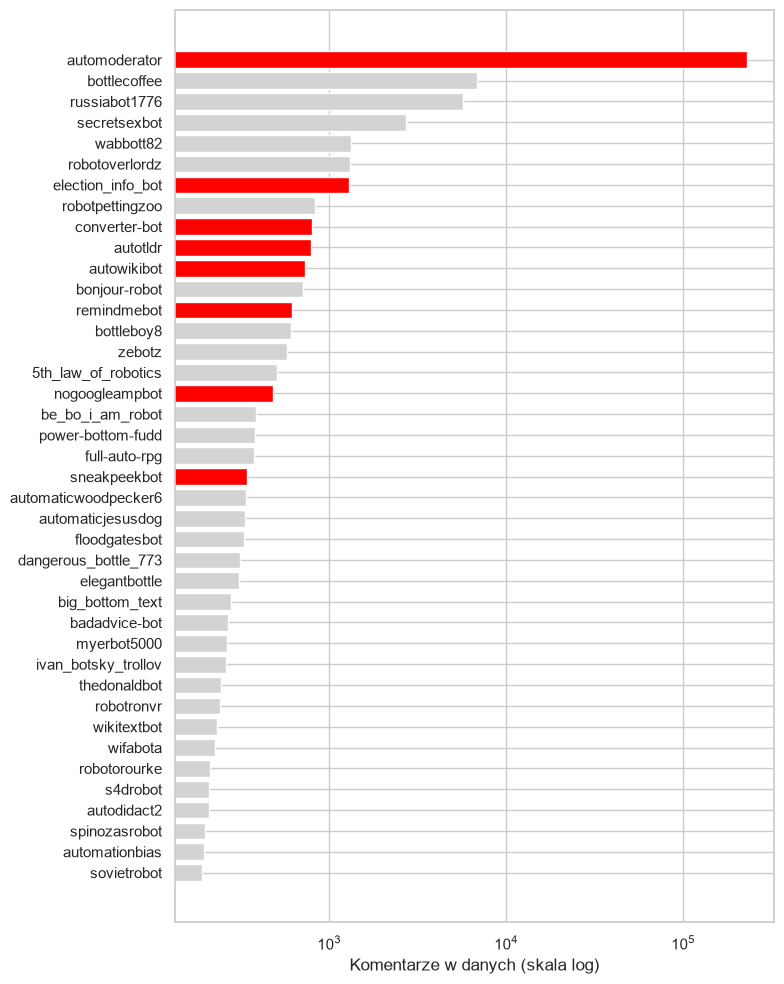

In [100]:
top_name = by_name.head(40)
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(top_name.index[::-1], top_name["n_total"][::-1], color=np.where(top_name.index[::-1].isin(BOTS), "red", "lightgray"))
ax.set_xscale("log")
ax.set_xlabel("Komentarze w danych (skala log)")
plt.tight_layout()
plt.show()

## 7. Siatka progów

In [101]:
def drop_summary(values, column="n", data=None):
    data = author_counts if data is None else data
    rows = []
    for value in values:
        high = data[data[column] >= value]
        part = high.groupby(["subreddit", "cycle"]).agg(n_accounts=("author", "size"), n_dropped=("n", "sum"))
        part = file_totals.to_frame().join(part).fillna(0)
        part["share_dropped"] = part["n_dropped"] / part["n_file"]
        part.insert(0, "threshold", value)
        rows.append(part.reset_index())
    return pd.concat(rows, ignore_index=True)


grid = drop_summary(THRESHOLDS)
grid.to_csv(BOTS_DIR / "grid_by_file.csv", index=False)
share_table = grid.pivot_table(index=["subreddit", "cycle"], columns="threshold", values="share_dropped")
accounts_table = grid.pivot_table(index=["subreddit", "cycle"], columns="threshold", values="n_accounts").astype(int)

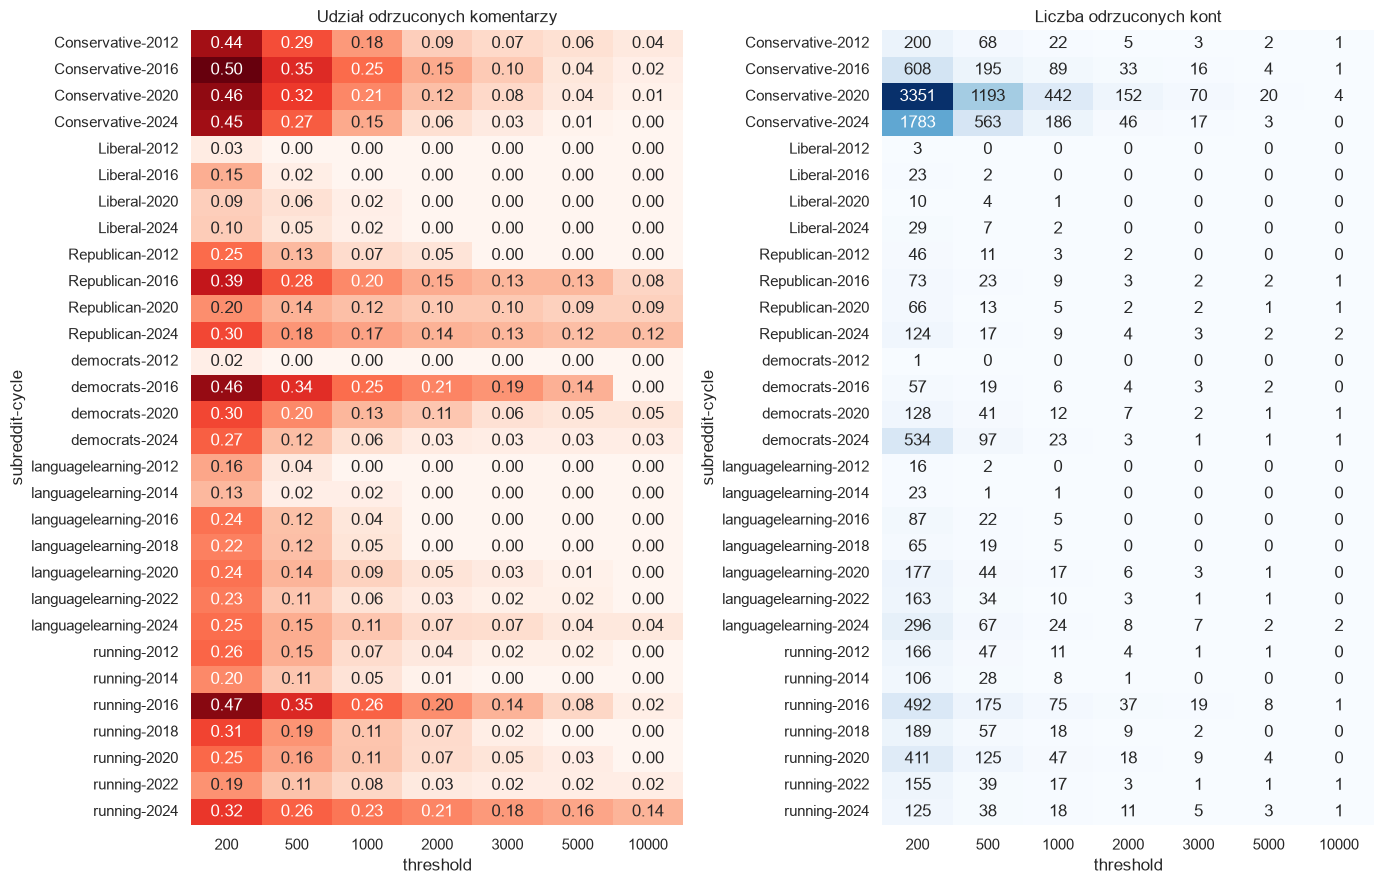

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
sns.heatmap(share_table, annot=True, fmt=".2f", cmap="Reds", ax=axes[0], cbar=False)
axes[0].set_title("Udział odrzuconych komentarzy")
sns.heatmap(accounts_table, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Liczba odrzuconych kont")
plt.tight_layout()
plt.show()

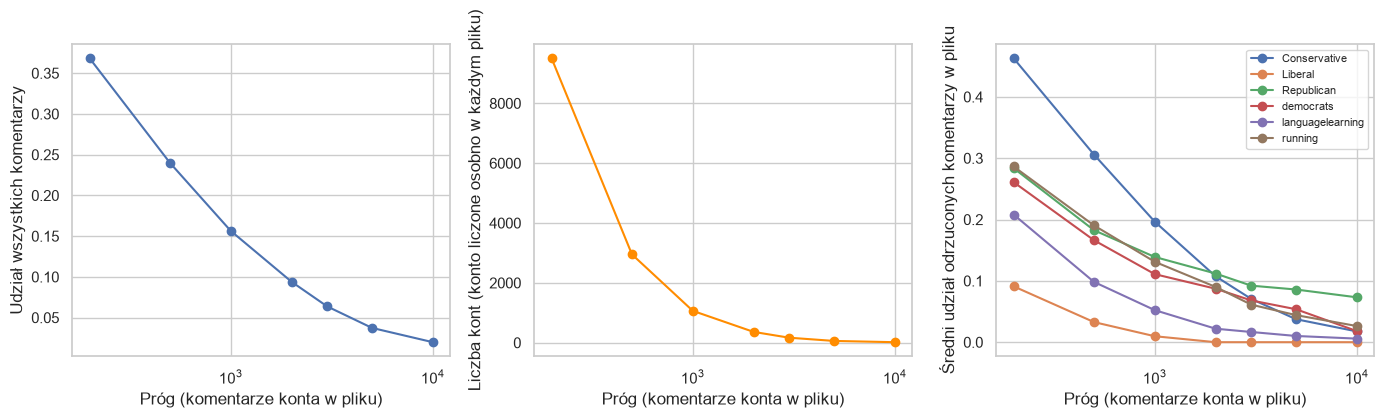

In [103]:
total = grid.groupby("threshold").agg(n_dropped=("n_dropped", "sum"), n_accounts=("n_accounts", "sum"))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(total.index, total["n_dropped"] / n_all, marker="o")
axes[0].set_ylabel("Udział wszystkich komentarzy")
axes[1].plot(total.index, total["n_accounts"], marker="o", color="darkorange")
axes[1].set_ylabel("Liczba kont (konto liczone osobno w każdym pliku)")
for subreddit, part in grid.groupby("subreddit"):
    axes[2].plot(part.groupby("threshold")["share_dropped"].mean(), marker="o", label=subreddit)
axes[2].set_ylabel("Średni udział odrzuconych komentarzy w pliku")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Próg (komentarze konta w pliku)")
plt.tight_layout()
plt.show()

## 8. Kto odpada przy progu

In [104]:
columns = ["n_files_hit", "n_dropped", "max_n", "max_file", "per_week", "per_thread", "name_pattern"]
dropped_rows = []
for threshold in THRESHOLDS:
    hit = author_counts[author_counts["n"] >= threshold]
    dropped = hit.groupby("author").agg(n_files_hit=("cycle", "size"), n_dropped=("n", "sum"))
    dropped = dropped.join(accounts[["max_n", "max_file", "per_week", "per_thread", "name_pattern"]])
    dropped.insert(0, "threshold", threshold)
    dropped_rows.append(dropped.reset_index())
dropped_accounts = pd.concat(dropped_rows, ignore_index=True)
dropped_accounts.to_csv(BOTS_DIR / "grid_dropped_accounts.csv", index=False)

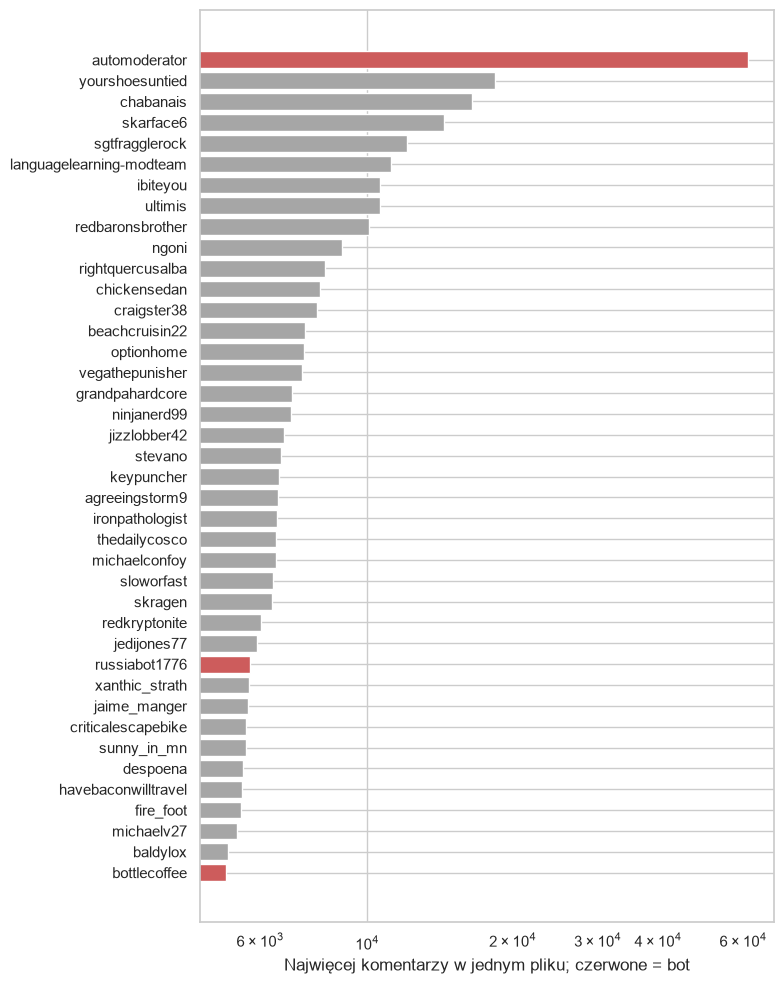

In [105]:
heaviest = accounts.sort_values("max_n", ascending=False).head(40)
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(heaviest.index[::-1], heaviest["max_n"][::-1], color=np.where(heaviest["name_pattern"][::-1], "indianred", "0.65"))
ax.set_xscale("log")
ax.set_xlabel("Najwięcej komentarzy w jednym pliku; czerwone = bot")
plt.tight_layout()
plt.show()

In [106]:
PREVIEW = 5000
preview = dropped_accounts[dropped_accounts["threshold"] == PREVIEW].set_index("author").sort_values("n_dropped", ascending=False)
print(f"próg {PREVIEW}: {len(preview)} kont, {int(preview['n_dropped'].sum())} komentarzy")
preview[columns].head(100)

próg 5000: 44 kont, 575501 komentarzy


,n_files_hit,n_dropped,max_n,max_file,per_week,per_thread,name_pattern
author,,,,,,,
automoderator,9,200334,61417,running 2024,590.5,1.0,True
chabanais,3,32063,16515,Conservative 2016,157.3,3.4,False
ultimis,3,23634,10613,Conservative 2020,101.1,2.4,False
redbaronsbrother,2,19651,10101,Republican 2024,160.3,3.0,False
ibiteyou,2,18474,10623,Republican 2016,103.1,4.0,False
yourshoesuntied,1,18396,18396,running 2016,175.2,6.3,False
skarface6,1,14448,14448,Conservative 2020,137.6,2.9,False
sgtfragglerock,1,12084,12084,Conservative 2020,151.0,1.6,False
languagelearning-modteam,1,11193,11193,languagelearning 2024,107.6,1.0,False


In [107]:
PREVIEW = 2000
preview = dropped_accounts[dropped_accounts["threshold"] == PREVIEW].set_index("author").sort_values("n_dropped", ascending=False)
print(f"próg {PREVIEW}: {len(preview)} kont, {int(preview['n_dropped'].sum())} komentarzy")
preview[columns].head(100)

próg 2000: 309 kont, 1447006 komentarzy


,n_files_hit,n_dropped,max_n,max_file,per_week,per_thread,name_pattern
author,,,,,,,
automoderator,15,222944,61417,running 2024,590.5,1.0,True
chabanais,3,32063,16515,Conservative 2016,157.3,3.4,False
ibiteyou,5,27064,10623,Republican 2016,103.1,4.0,False
ultimis,3,23634,10613,Conservative 2020,101.1,2.4,False
redbaronsbrother,2,19651,10101,Republican 2024,160.3,3.0,False
skarface6,2,18499,14448,Conservative 2020,137.6,2.9,False
yourshoesuntied,1,18396,18396,running 2016,175.2,6.3,False
sloworfast,3,12299,6380,running 2016,72.5,5.8,False
sgtfragglerock,1,12084,12084,Conservative 2020,151.0,1.6,False


## 9. Komentarze najaktywniejszych kont

In [108]:
for name in accounts[accounts["max_n"] >= 5000].sort_values("max_n", ascending=False).index:
    show_single_comment(name, 5)

automoderator | komentarzy: 228971 | najwięcej: 61417 (running 2024) | na tydzień: 590.5
   - Welcome to r/Running! Your post has been automatically removed and put in a queue for human review. This protects the sub from spam and trolling as well as prompts users to familiarize themselves with our community. All posts are queued - [...]
   - **Join:** * /r/KamalaHarris * /r/TimWalz * /r/democrats **[Register to vote](https://www.iwillvote.com/)** *I am a bot, and this action was performed automatically. Please [contact the moderators of this [...]
   - Your submission has been automatically removed because your account does not meet the minimum post karma, or minimum comment karma, *and/or* account age requirements of /r/democrats. If you are new to reddit, we suggest you read: * [reddit [...]
   - Welcome to r/Running! Your post has been automatically removed and put in a queue for human review. This protects the sub from spam and trolling as well as prompts users to familiarize thems

In [109]:
BOTS.append("languagelearning-modteam")

## 10. Maksymalna liczba komentarzy w tygodniu

In [110]:
WEEKLY_THRESHOLDS = [50, 100, 200, 300, 500, 1000]
weekly_grid = drop_summary(WEEKLY_THRESHOLDS, "max_week")
weekly_grid.to_csv(BOTS_DIR / "grid_weekly.csv", index=False)
weekly_share_table = weekly_grid.pivot_table(index=["subreddit", "cycle"], columns="threshold", values="share_dropped")
weekly_accounts_table = weekly_grid.pivot_table(index=["subreddit", "cycle"], columns="threshold", values="n_accounts").astype(int)

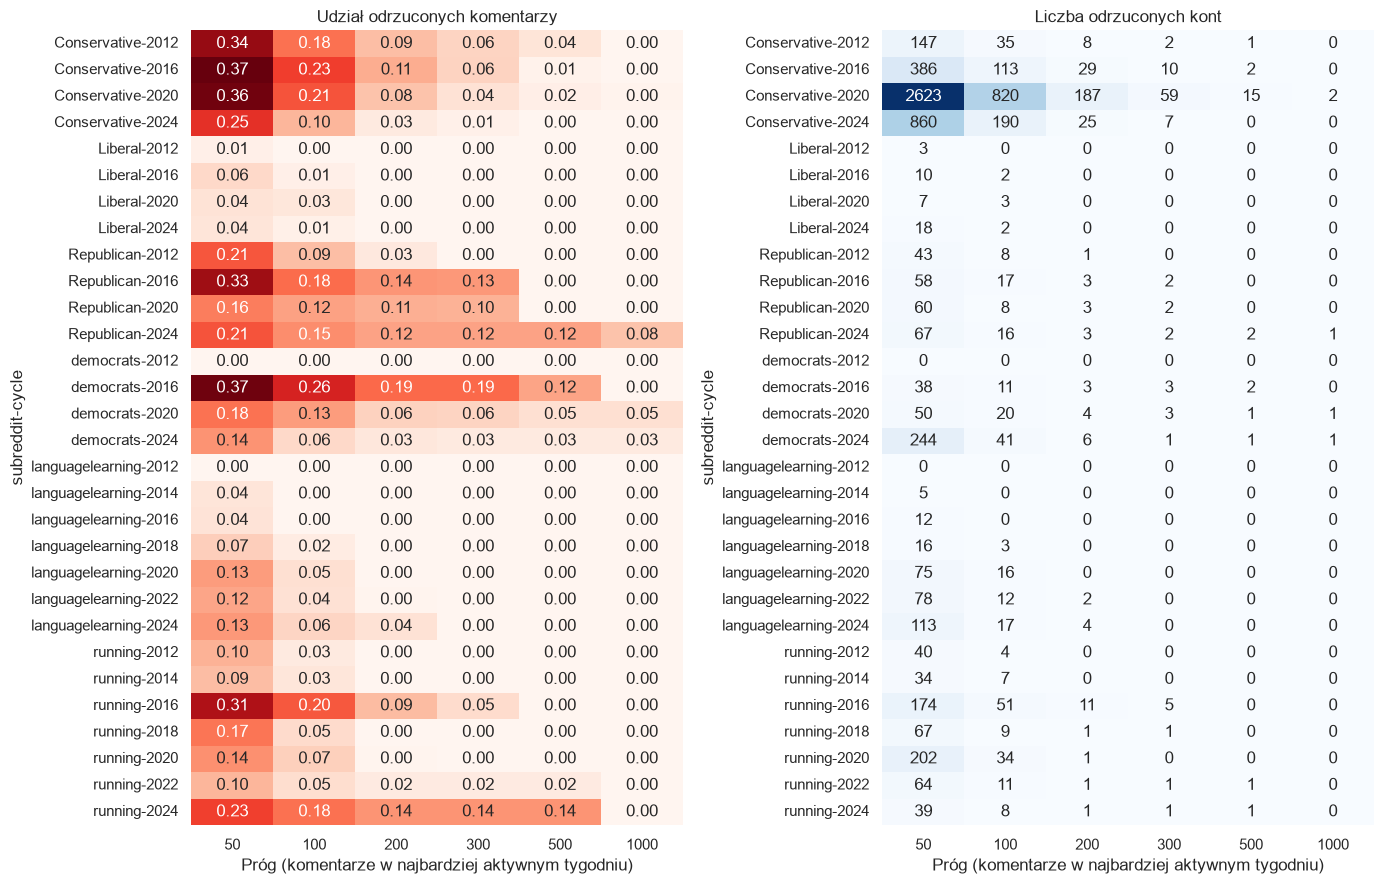

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
sns.heatmap(weekly_share_table, annot=True, fmt=".2f", cmap="Reds", ax=axes[0], cbar=False)
axes[0].set_title("Udział odrzuconych komentarzy")
sns.heatmap(weekly_accounts_table, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Liczba odrzuconych kont")
for ax in axes:
    ax.set_xlabel("Próg (komentarze w najbardziej aktywnym tygodniu)")
plt.tight_layout()
plt.show()

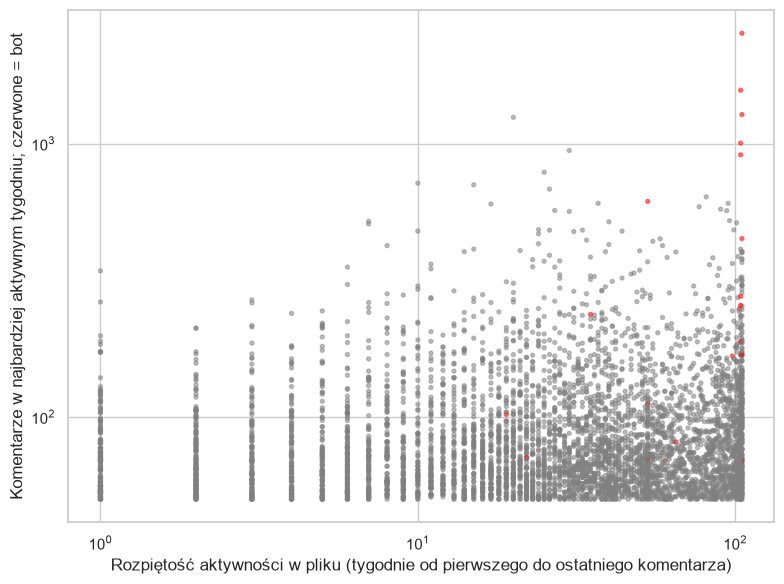

In [112]:
big = author_counts[author_counts["max_week"] >= 50]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(big["span_weeks"], big["max_week"], s=8, alpha=0.5, c=np.where(big["author"].isin(BOTS), "red", "0.5"))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Rozpiętość aktywności w pliku (tygodnie od pierwszego do ostatniego komentarza)")
ax.set_ylabel("Komentarze w najbardziej aktywnym tygodniu; czerwone = bot")
plt.tight_layout()
plt.show()

In [123]:
PREVIEW_WEEKLY = 200
hits = author_counts[author_counts["max_week"] >= PREVIEW_WEEKLY].sort_values("max_week", ascending=False)
weekly_preview = hits.drop_duplicates("author").set_index("author")[["subreddit", "cycle", "n", "n_weeks", "span_weeks", "max_week", "peak_week"]]
weekly_preview["n_files_hit"] = hits.groupby("author").size()
weekly_preview["share_in_peak"] = (weekly_preview["max_week"] / weekly_preview["n"]).round(2)
weekly_preview["name_pattern"] = weekly_preview.index.str.contains(NAME_RE)
weekly_preview["in_BOTS"] = weekly_preview.index.isin(BOTS)
weekly_preview = weekly_preview[~weekly_preview.index.isin(accounts[accounts["max_n"] >= 5000].sort_values("max_n", ascending=False).index)]
weekly_preview.to_csv(BOTS_DIR / "grid_weekly_accounts.csv")
print(f"{PREVIEW_WEEKLY} komentarzy w tygodniu: {len(weekly_preview)} kont, w tym {int(weekly_preview['in_BOTS'].sum())} z listy BOTS")
weekly_preview[~weekly_preview["in_BOTS"]]

200 komentarzy w tygodniu: 243 kont, w tym 0 z listy BOTS


,subreddit,cycle,n,n_weeks,span_weeks,max_week,peak_week,n_files_hit,share_in_peak,name_pattern,in_BOTS
author,,,,,,,,,,,
baxterblog,Conservative,2020,3945,19,20,1247,2020-11-02,1,0.32,False,False
knicks1986,Conservative,2020,3813,26,30,943,2020-08-24,1,0.25,False,False
ant0n61,Conservative,2020,3822,25,25,785,2020-10-26,1,0.21,False,False
sconce2600,Conservative,2020,1102,9,10,716,2020-11-02,1,0.65,False,False
alexlincoln2,Conservative,2016,2919,15,15,706,2016-03-07,1,0.24,False,False
...,...,...,...,...,...,...,...,...,...,...,...
powerful-pick-8416,democrats,2024,577,9,9,201,2023-09-04,1,0.35,False,False
misfirehurricane,Conservative,2020,1029,25,25,201,2020-06-01,1,0.20,False,False
leading-bowl-8416,Conservative,2020,1417,20,24,201,2021-02-08,1,0.14,False,False


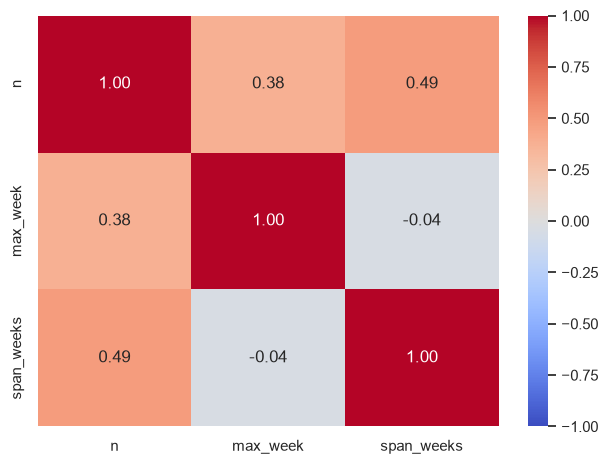

In [127]:
corr = weekly_preview[["n", "max_week", "span_weeks"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

In [137]:
def show_comments_batch(names, comments=3, range=(None, None)):
    names = list(names)[slice(*range)]
    wanted = {name.lower().encode() for name in names}
    found = {key: [] for key in wanted}
    seen = dict.fromkeys(wanted, 0)
    rng = random.Random(42)
    author_re = re.compile(rb'"author": *"([^"]+)"')

    files = author_counts[
        author_counts["author"].isin(names)
    ][["subreddit", "cycle"]].drop_duplicates()

    for subreddit, cycle in files.itertuples(index=False):
        path = RAW_DIR / f"r_{subreddit}_comments_{cycle}.jsonl"
        with open(path, "rb") as file:
            for line in file:
                match = author_re.search(line)
                if not match:
                    continue

                key = match.group(1).lower()
                if key not in wanted:
                    continue

                seen[key] += 1
                body = json.loads(line)["body"]
                if len(found[key]) < comments:
                    found[key].append(body)
                else:
                    slot = rng.randrange(seen[key])
                    if slot < comments:
                        found[key][slot] = body

    for name in names:
        row = accounts.loc[name]
        print(
            f"{name} | komentarzy: {row['n_total']} | najwięcej: "
            f"{row['max_n']} ({row['max_file']}) | na tydzień: {row['per_week']}"
        )
        for text in found[name.lower().encode()]:
            print("   -", textwrap.shorten(str(text), 250))
        print()


In [138]:
names = weekly_preview[~weekly_preview["in_BOTS"]].sort_values("max_week", ascending=False).index
show_comments_batch(names, 3, range=(0, 50))

baxterblog | komentarzy: 4153 | najwięcej: 3945 (Conservative 2020) | na tydzień: 207.6
   - If it’s sustainable and affordable, yes.
   - They could have started by actually negotiating with Republicans instead of ramming it through.
   - Yep. And if military service is such a key desire for them, ask what happened to Tulsi? Or why they love Obama?

knicks1986 | komentarzy: 3818 | najwięcej: 3813 (Conservative 2020) | na tydzień: 146.7
   - The nicest actor you can find. He retired from acting to raise his kids after his wife sadly passed away. I was looking forward to him possibly making a comeback and hopefully he still will. Sadly as New Yorkers we have two of the worst leaders [...]
   - I’m just being objective. Thank You And stay safe
   - Wait a minute I thought Antifa was only an idea? By the way I love how the liberal trolls quickly downvote our posts like it’s actually going to stay that way 😂.

ant0n61 | komentarzy: 4192 | najwięcej: 3822 (Conservative 2020) | na tydzień: 1

In [139]:
show_comments_batch(["koolkeith987"], 20)

koolkeith987 | komentarzy: 342 | najwięcej: 342 (running 2018) | na tydzień: 342.0
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.
   - Ur a bitch.



In [140]:
show_comments_batch(names, 3, range=(51, 100))

philpips | komentarzy: 5333 | najwięcej: 4556 (running 2016) | na tydzień: 51.8
   - Smoking all the time is also tres French.
   - Knutsford is a place near Cheshire. It's where rich people live.
   - Did /u/anonymouswritings finish his marathon faster than /u/kinsibit? I'm on tenterhooks here.

blazing420kilk | komentarzy: 1196 | najwięcej: 1165 (Conservative 2020) | na tydzień: 53.0
   - Those same nutjobs are nowhere to be seen when they're actually needed. How convenient
   - Would it be enough seating?
   - Time to Cancel COVID-19, where's my twitter...

not_a_democrat_ | komentarzy: 1903 | najwięcej: 1903 (Conservative 2020) | na tydzień: 86.5
   - Wow, this post got downvoted. Weird, only leftists seem to massively downvote shit here, and this post is about MLK. It's almost as if they have absolutely no respect for him....
   - When you put it that way, yeah, I can see that, because the logic they used for the rest of the game is equally as stupid
   - Drop an anti-matter bomb 

In [141]:
show_comments_batch(names, 3, range=(101, 150))

stickykeysmcgee | komentarzy: 1108 | najwięcej: 1104 (Conservative 2012) | na tydzień: 78.9
   - a real civilian? What do you mean?
   - Even IF that were true, it wouldn't disprove my point. You take away the cheap labor force, the economy crashes. If you don't understand why, you can ask for further explanation. Although bigbee's comment above her covers it well: >We had a [...]
   - Maybe. Maybe not. The difference is, the Dems have much of the moderate vote staked out. Over time the GOP can take some of those votes, but it wont happen overnight. So they would be trading possible future votes for a net loss from the social [...]

darlenapeugh | komentarzy: 345 | najwięcej: 345 (Conservative 2020) | na tydzień: 69.0
   - 𝖴𝗋 𝖺 𝗅𝖾𝖿𝗍𝗒 𝗌𝗁𝗂𝗅𝗅 𝖺𝗇𝖽 𝗎 𝖽𝗈𝗇𝗍 𝖻𝖾𝗅𝗂𝖾𝗏𝖾 𝗍𝗁𝖺𝗍𝗍 𝖸𝗈𝗎𝗋 𝖼𝗈𝗆𝗆𝖾𝗇𝗍 𝗁𝗂𝗌𝗍𝗈𝗋𝗒 𝗂𝗌 𝖿𝗎𝗅𝗅 𝗈𝖿 𝗅𝖾𝖿𝗍𝗂𝗌𝗍 𝖻𝗎𝗅𝗌𝗁𝗂𝗍𝗍 𝗀𝗎𝗒𝗌 𝖽𝗈𝗇'𝗍 𝖿𝖺𝗅𝗅 𝖿𝗈𝗋 𝗍𝗁𝗂𝗌 𝖼𝗋𝖺𝗉.. 𝖳𝗁𝖾 𝖢𝗈𝗆𝗆𝗎𝗇𝗂𝗌𝗍𝗌 𝖺𝗋𝖾 𝖻𝗋𝗂𝗀𝖺𝖽𝗂𝗇𝗀 𝖺𝗋𝖾 𝗌𝗎𝖻𝗋𝖾𝖽𝖽𝗂𝗍 𝗉𝗎𝗌𝗁𝗂𝗇𝗀 𝗍𝗁𝗂𝗌 𝖼𝗋𝖺𝗉 𝗂𝗇 𝖺𝗇 𝖺𝗍𝗍𝖾𝗆𝗉𝗍 𝗍𝗈 𝖼𝗈𝗇𝗏𝗂𝗇𝖼𝖾 𝗒𝗈𝗎 𝗇𝗈𝗍 𝗍𝗈 𝗍𝖺𝗄𝖾 𝗈𝗇 𝖥𝖺𝖼𝖾𝖻𝗈𝗈 𝗍𝗁𝖾 [...]
   - https://imgur.c

In [142]:
show_comments_batch(names, 3, range=(151, 200))

-brutusbuckeye | komentarzy: 495 | najwięcej: 466 (Conservative 2020) | na tydzień: 35.8
   - They are. The Left are the most hateful and vitriolic people you'll ever hear from.
   - What the heck did you just stumble on, OP? Walter Cronkite over here...
   - There's alot of this kind of stuff out there and I like it.

soulofwakanda | komentarzy: 373 | najwięcej: 247 (Conservative 2020) | na tydzień: 30.9
   - What about when Biden somehow had a surge of 150k Michigan votes without Trump gaining a single in his tally? That's not suspect to you?
   - I'm not saying Trump would win CA. Obviously not. I'm asking if they're actually counting these fucking votes
   - It's like Floyd said, you didn't hear a single thing about Donald Trump being racist until he ran for president

potatoumaru | komentarzy: 1574 | najwięcej: 1101 (Conservative 2024) | na tydzień: 31.5
   - Kathleen Kennedy killed Battlestar Galactica
   - Lets take a look at any left wing news articles. They're worse with their

In [143]:
show_comments_batch(names, 3, range=(201, 250))

fenway1197 | komentarzy: 260 | najwięcej: 260 (Conservative 2020) | na tydzień: 130.0
   - i dont think this is real news
   - We should go all in on this to make it real to leftists that after 6 weeks, the fetus is considered a human being: 1. Child support payments start after 6 weeks 2. The child is a US citizen so the mother cannot be deported 3. You can collect [...]
   - Conservatives - "But what about the rubber made for the tires? That's made of oil and we all know how much you hate oil!" &#x200B; We got you AOC!

deverusx | komentarzy: 510 | najwięcej: 510 (Conservative 2020) | na tydzień: 102.0
   - *"People who have contributed nothing to society are entitled to exaclty what they have contributed."* \- James Hing. Go back to where you came from and contribute to your own house, not take from ours.
   - Agreed. The Left just completely ignores everything that has ever happened since the dawn of Mesopotamia onward and only see history beginning with europeans landing on these 

In [135]:
BOTS.append("koolkeith987 ")

## 11. Decyzja: lista do odrzucenia

In [146]:
WEEKLY_THRESHOLD = None
APPROVED_BOTS = set(BOTS)
KEEP_ANYWAY = set()

In [147]:
author_counts["by_name"] = author_counts["author"].isin(APPROVED_BOTS)
author_counts["by_weekly"] = False
if WEEKLY_THRESHOLD is not None:
    author_counts["by_weekly"] = ((author_counts["max_week"] >= WEEKLY_THRESHOLD) & ~author_counts["author"].isin(KEEP_ANYWAY)
                                  & ~author_counts["by_name"])
author_counts["dropped"] = author_counts["by_name"] | author_counts["by_weekly"]
author_counts["reason"] = np.select([author_counts["by_name"], author_counts["by_weekly"]], ["nazwa", "tydzień"], default="")

exclude = author_counts[author_counts["dropped"]].groupby("author").agg(n_files=("cycle", "size"), n_dropped=("n", "sum"),
                                                                       reason=("reason", lambda r: "+".join(sorted(set(r)))))
exclude = exclude.join(accounts[["max_file", "per_week", "per_thread", "name_pattern"]])
exclude = exclude.sort_values("n_dropped", ascending=False)
exclude.to_csv(BOTS_DIR / "exclude_accounts.csv")
print(f"tydzień {WEEKLY_THRESHOLD}: {len(exclude)} kont do odrzucenia, {int(exclude['n_dropped'].sum())} komentarzy ({exclude['n_dropped'].sum() / n_all:.1%})")
exclude.head(100)

tydzień None: 16 kont do odrzucenia, 246229 komentarzy (1.6%)


,n_files,n_dropped,reason,max_file,per_week,per_thread,name_pattern
author,,,,,,,
automoderator,25,228971,nazwa,running 2024,590.5,1.0,True
languagelearning-modteam,2,11305,nazwa,languagelearning 2024,107.6,1.0,False
election_info_bot,1,1292,nazwa,democrats 2020,25.3,1.0,True
converter-bot,5,795,nazwa,running 2020,52.7,1.7,True
autotldr,13,790,nazwa,democrats 2016,13.0,1.0,True
autowikibot,5,725,nazwa,running 2014,6.1,1.1,True
remindmebot,18,618,nazwa,running 2020,1.7,1.0,True
nogoogleampbot,6,481,nazwa,Conservative 2020,23.4,1.2,True
sneakpeekbot,9,345,nazwa,running 2018,5.3,1.0,True


In [ ]:
print("BOT_ACCOUNTS =", sorted(exclude.index[exclude["reason"].str.contains("nazwa")]))
print(f"Number of bots: {len(APPROVED_BOTS)}")
print(f"WEEKLY_THRESHOLD: {WEEKLY_THRESHOLD}")

BOT_ACCOUNTS = ['automoderator', 'autotldr', 'autowikibot', 'converter-bot', 'dadbot_3000', 'election_info_bot', 'haikusbot', 'helperbot_', 'languagelearning-modteam', 'nogoogleampbot', 'remindmebot', 'robotsfromthefuture', 'sneakpeekbot', 'userleansbot', 'wikisummarizerbot', 'youtubefactsbot']
Number of bots: 17
WEEKLY_THRESHOLD: None


: 

## 12. Podsumowanie według pliku

In [150]:
REASONS = ["nazwa", "tydzień"]
by_reason = author_counts[author_counts["dropped"]].groupby(["subreddit", "cycle", "reason"])["n"].sum().unstack(fill_value=0)
summary_files = file_totals.to_frame().join(by_reason).fillna(0)
for reason in REASONS:
    if reason not in summary_files:
        summary_files[reason] = 0
summary_files["share_dropped"] = summary_files[REASONS].sum(axis=1) / summary_files["n_file"]
summary_files.to_csv(BOTS_DIR / "summary_files.csv")
summary_files.round(3)

n_file    nazwa  tydzień  share_dropped
subreddit        cycle                                          
Conservative     2012    273646     34.0        0          0.000
                 2016    795896   5043.0        0          0.006
                 2020   4561472  19372.0        0          0.004
                 2024   2142856   4091.0        0          0.002
Liberal          2012     21176     97.0        0          0.005
                 2016     53196    399.0        0          0.008
                 2020     56709    147.0        0          0.003
                 2024    119776    427.0        0          0.004
Republican       2012     83405      5.0        0          0.000
                 2016    129486    806.0        0          0.006
                 2020    281849  25605.0        0          0.091
                 2024    272126  22783.0        0          0.084
democrats        2012     12475      9.0        0          0.001
                 2016     96737   2360.0        0          0.024
                 2020    270199  13984.0        0          0.052
                 2024    878210  22436.0        0          0.026
languagelearning 2012     34326      0.0        0          0.000
                 2014     54481    334.0        0          0.006
                 2016    155677   1861.0        0          0.012
                 2018    134408   1107.0        0          0.008
                 2020    386087   4365.0        0          0.011
                 2022    334289   2669.0        0          0.008
                 2024    700233  28659.0        0          0.041
running          2012    309677      1.0        0          0.000
                 2014    248147    328.0        0          0.001
                 2016    796930   4595.0        0          0.006
                 2018    338331   2706.0        0          0.008
                 2020    959075   9591.0        0          0.010
                 2022    455575  10983.0        0          0.024
                 2024    447162  61432.0        0          0.137

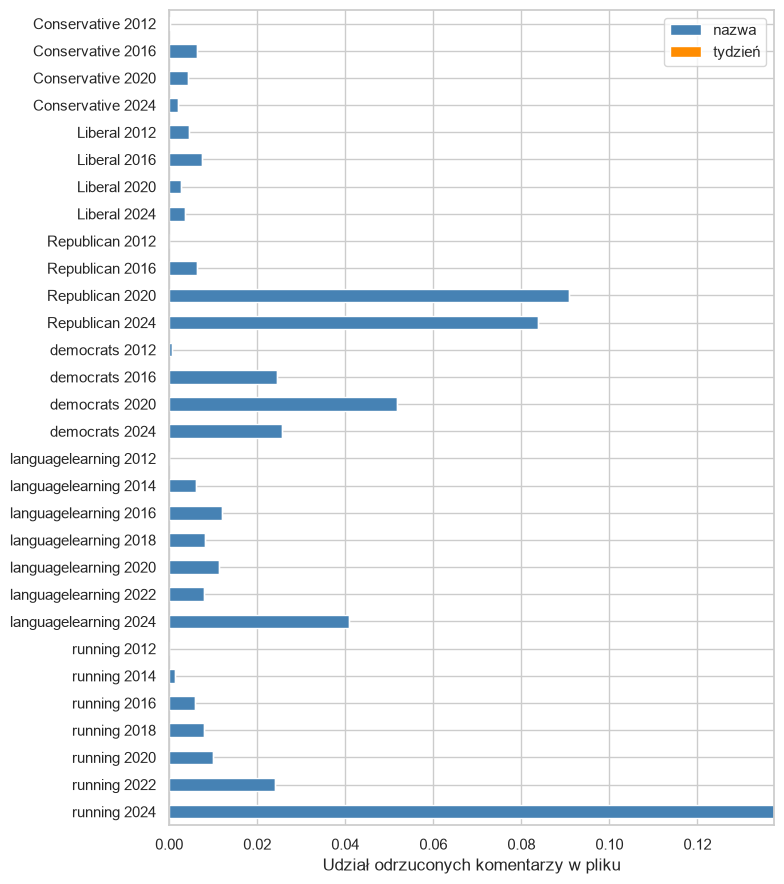

In [151]:
shares = summary_files[REASONS].div(summary_files["n_file"], axis=0)
shares.index = [f"{subreddit} {cycle}" for subreddit, cycle in shares.index]
shares[::-1].plot.barh(stacked=True, figsize=(8, 9), color={"nazwa": "steelblue", "tydzień": "darkorange"})
plt.xlabel("Udział odrzuconych komentarzy w pliku")
plt.tight_layout()
plt.show()

Łącznie odrzucono 246,229 komentarzy


nazwa  tydzień    razem
subreddit        cycle                           
running          2024   61432.0        0  61432.0
languagelearning 2024   28659.0        0  28659.0
Republican       2020   25605.0        0  25605.0
                 2024   22783.0        0  22783.0
democrats        2024   22436.0        0  22436.0
Conservative     2020   19372.0        0  19372.0
democrats        2020   13984.0        0  13984.0
running          2022   10983.0        0  10983.0
                 2020    9591.0        0   9591.0
Conservative     2016    5043.0        0   5043.0
running          2016    4595.0        0   4595.0
languagelearning 2020    4365.0        0   4365.0
Conservative     2024    4091.0        0   4091.0
running          2018    2706.0        0   2706.0
languagelearning 2022    2669.0        0   2669.0
democrats        2016    2360.0        0   2360.0
languagelearning 2016    1861.0        0   1861.0
                 2018    1107.0        0   1107.0
Republican       2016     806.0        0    806.0
Liberal          2024     427.0        0    427.0
                 2016     399.0        0    399.0
languagelearning 2014     334.0        0    334.0
running          2014     328.0        0    328.0
Liberal          2020     147.0        0    147.0
                 2012      97.0        0     97.0
Conservative     2012      34.0        0     34.0
democrats        2012       9.0        0      9.0
Republican       2012       5.0        0      5.0
running          2012       1.0        0      1.0
languagelearning 2012       0.0        0      0.0

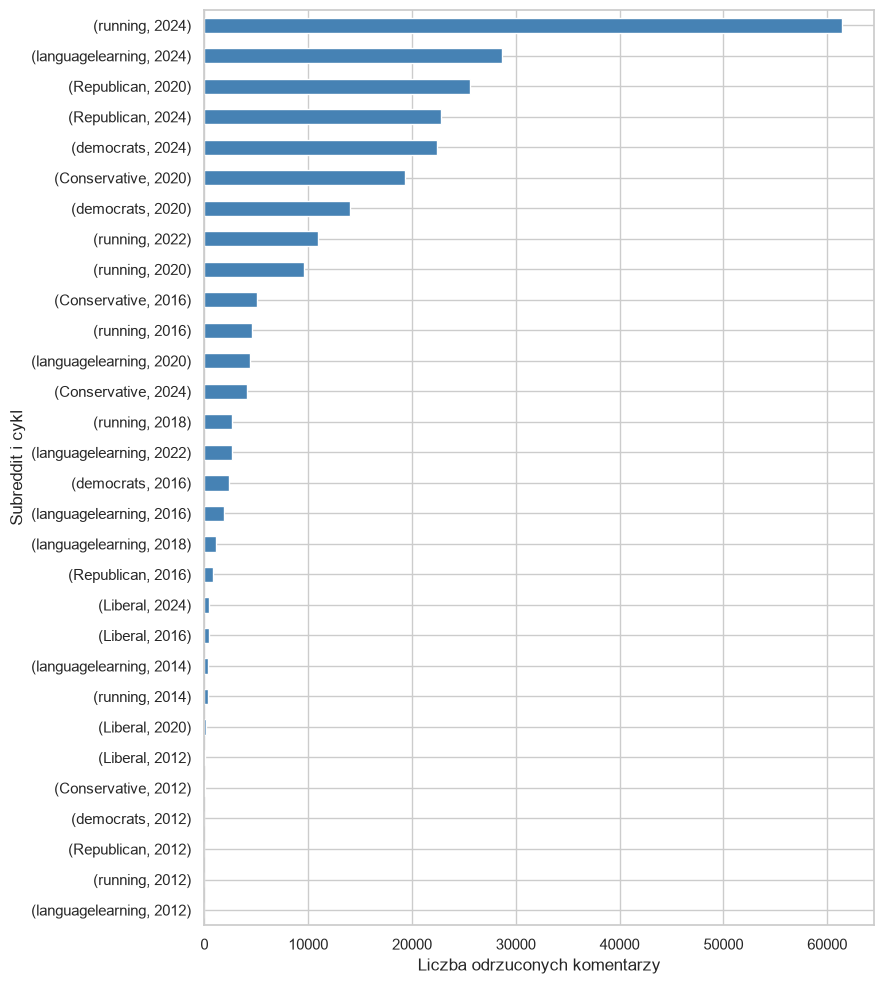

In [152]:
dropped_counts = summary_files[REASONS].copy()
dropped_counts["razem"] = dropped_counts.sum(axis=1)

print(f"Łącznie odrzucono {int(dropped_counts['razem'].sum()):,} komentarzy")
display(dropped_counts.sort_values("razem", ascending=False))

dropped_counts["razem"].sort_values().plot.barh(figsize=(9, 10), color="steelblue")
plt.xlabel("Liczba odrzuconych komentarzy")
plt.ylabel("Subreddit i cykl")
plt.tight_layout()
plt.show()